In [16]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Reformat Quantom sensor data

In this notebook, we take daily DOC data, estimated by a regression between high resolution FDOM data and spot samples of DOC concentration. Data were collected as part of the Quantom project and are not published yet, so **should not be distributed with the cleaned vannmiljø dataset yet** (at least, not without permission from Benoit Demars).

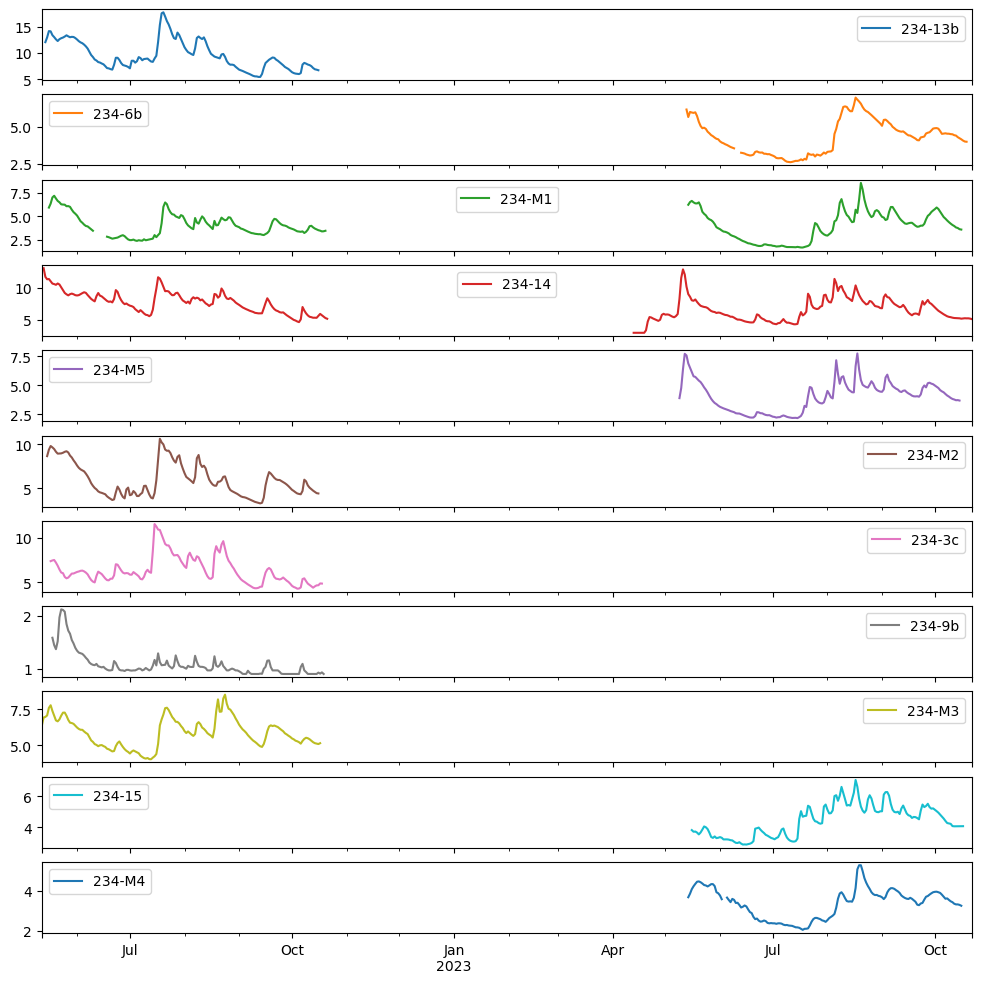

,Date,234-13b,234-6b,234-M1,234-14,234-M5,234-M2,234-3c,234-9b,234-M3,234-15,234-M4
0,2022-05-12,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6.373114,NaN,NaN
1,2022-05-13,NaN,NaN,NaN,13.092531,NaN,NaN,NaN,NaN,6.922135,NaN,NaN
2,2022-05-14,12.037167,NaN,NaN,11.734969,NaN,NaN,NaN,NaN,6.967500,NaN,NaN
3,2022-05-15,12.945854,NaN,NaN,11.358792,NaN,8.671490,NaN,NaN,7.068000,NaN,NaN
4,2022-05-16,14.143479,NaN,5.916324,11.400667,NaN,9.402043,NaN,NaN,7.592135,NaN,NaN


In [18]:
quantom_chem_fpath = r"/home/jovyan/shared/common/norsink/waterchem/quantom/quantom_sensor_doc_data.xlsx"
wide_df = pd.read_excel(quantom_chem_fpath)

wide_df.set_index('Date').plot(subplots=True, sharex=True, figsize=(12, 12))
plt.xlabel('')
plt.show()

wide_df.head()

In [4]:
quantom_meta_fpath = r"/home/jovyan/shared/common/norsink/waterchem/quantom/tana_sensor_sites_outlet_coords.csv"
meta_df = pd.read_csv(quantom_meta_fpath)
meta_df

,WaterLocationCode,WaterLocationID,Name,lat,lon,Contractor
0,234-M1,-1,Tana (Polmak),70.07421,28.05766,JHI
1,234-M2,-2,Anarjohka,69.39858,25.84324,JHI
2,234-M3,-3,Karasjohka,69.39521,25.14476,JHI
3,234-M4,-4,Utsjoki (Patoniva),69.78289,27.00055,JHI
4,234-M5,-5,Iesjohka (NVE),69.43822,25.00019,JHI
5,234-3c,-6,Skierrejohka,69.32819,24.01093,JHI
6,234-9b,-7,Darjohka,69.96774,26.42399,JHI
7,234-13b,-8,Mareveadji,69.20015,25.68819,JHI
8,234-14,-9,Cærrogæsjokka,69.39010,24.47330,JHI
9,234-6b,-10,Raidejohka,69.53516,24.89018,JHI


In [11]:
long_df = wide_df.melt(
    id_vars=["Date"],                # columns to keep
    var_name="WaterLocationCode",   # new column with original column names
    value_name="DOC_mg_l"              # values column
)

# Drop NaNs
long_df = long_df.dropna(subset=['DOC_mg_l'])

long_df.head()

,Date,WaterLocationCode,DOC_mg_l
2,2022-05-14,234-13b,12.037167
3,2022-05-15,234-13b,12.945854
4,2022-05-16,234-13b,14.143479
5,2022-05-17,234-13b,14.092531
6,2022-05-18,234-13b,13.366698


In [19]:
df_merged = long_df.merge(
    meta_df,
    on="WaterLocationCode",
    how="left"   # keeps all observations
)

df_merged['ActivityName'] = 'Forskning'
df_merged['flag_lab_within_site'] = 0
df_merged['flag_lab_full_site'] = 0
df_merged['TOC_mg_l'] = np.nan

out_fpath = r"/home/jovyan/shared/common/norsink/waterchem/quantom/quantom_sensor_data_reformatted_for_vm.csv"
df_merged.to_csv(out_fpath, index=False)

df_merged

,Date,WaterLocationCode,DOC_mg_l,WaterLocationID,Name,lat,lon,Contractor,ActivityName,flag_lab_within_site,flag_lab_full_site,TOC_mg_l
0,2022-05-14,234-13b,12.037167,-8,Mareveadji,69.20015,25.68819,JHI,Forskning,0,0,NaN
1,2022-05-15,234-13b,12.945854,-8,Mareveadji,69.20015,25.68819,JHI,Forskning,0,0,NaN
2,2022-05-16,234-13b,14.143479,-8,Mareveadji,69.20015,25.68819,JHI,Forskning,0,0,NaN
3,2022-05-17,234-13b,14.092531,-8,Mareveadji,69.20015,25.68819,JHI,Forskning,0,0,NaN
4,2022-05-18,234-13b,13.366698,-8,Mareveadji,69.20015,25.68819,JHI,Forskning,0,0,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...
2063,2023-10-12,234-M4,3.348104,-4,Utsjoki (Patoniva),69.78289,27.00055,JHI,Forskning,0,0,NaN
2064,2023-10-13,234-M4,3.316000,-4,Utsjoki (Patoniva),69.78289,27.00055,JHI,Forskning,0,0,NaN
2065,2023-10-14,234-M4,3.316000,-4,Utsjoki (Patoniva),69.78289,27.00055,JHI,Forskning,0,0,NaN
2066,2023-10-15,234-M4,3.292271,-4,Utsjoki (Patoniva),69.78289,27.00055,JHI,Forskning,0,0,NaN


In [ ]:
# vm_chem_fpath = r"shared/common/norsink/waterchem/vannmiljo/metadata/vannmiljo_river_OC_site_metadata_first_clean_before_delineation.csv"
# vm_meta_fpath = r"shared/common/norsink/waterchem/vannmiljo/metadata/vannmiljo_river_OC_site-metadata_norway_allsites.csv"